# code_086 · Scalability and learned similarity

**Book:** section 17.5. A self-contained similarity-and-margin laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_17_GUIDE.md), [run evidence](../CHAPTER_17_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_086).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1786;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1786


<a id="retrieval"></a>
## Compare explicitly specified candidates

Generate train240/development120/final300 cases with twelve independent normal descriptors. The first two determine an XOR sign label, independently flipped with probability .05; ten descriptors are nuisance. Compare tuned standardized kNN, supervised two-dimensional linear NeighborhoodComponentsAnalysis (NCA) plus the same kNN grid, and a separately specified retrieval-augmented tabular stack. k[5,15,31] and uniform/distance weights are selected by development Brier score per kNN family. NCA uses PCA initialization, max_iter50, tol1e-5, and fixed seed; record iteration counts without asserting optimizer convergence. Normalize its map Frobenius norm to sqrt2 for the soft-distance temperature convention. This global rescaling does not change normalized inverse-distance kNN predictions.

The stack is inspired by TabR's use of retrieved features and labels, not an execution/reproduction of TabR, a neural encoder or ModernNCA. It uses top15 NCA neighbors, exp(-squared_distance/temperature) normalized weights, and context=[query's12raw descriptors,weighted neighbor label mean,12weighted original-feature differences,weighted squared distance]. Five-fold crossfitting fits the ENTIRE scaler/NCA inside each memory fold, then produces context for its disjoint query fold. Query labels never enter their own first-level fit or neighbor values. Original-feature differences remain comparable across rotating NCA fold axes. A fixed C1 logistic head with training-only meta scaling fits these out-of-fold contexts. Development Brier chooses temperature[.05,.2,1]. Deployment keys/memory use all training cases; final records never join memory. This finite implementation omits TabR's jointly learned neural key/value/predictor architecture.

Primary documentary references: [TabR preprint v2](https://arxiv.org/html/2307.14338v2), [official NCA](https://scikit-learn.org/1.9/modules/generated/sklearn.neighbors.NeighborhoodComponentsAnalysis.html), [kernel approximations](https://scikit-learn.org/1.9/modules/kernel_approximation.html), inspected20October2026. Live sklearn1.9.1 documentation is compared with executed1.9.0. Paper benchmark claims are not rerun here.


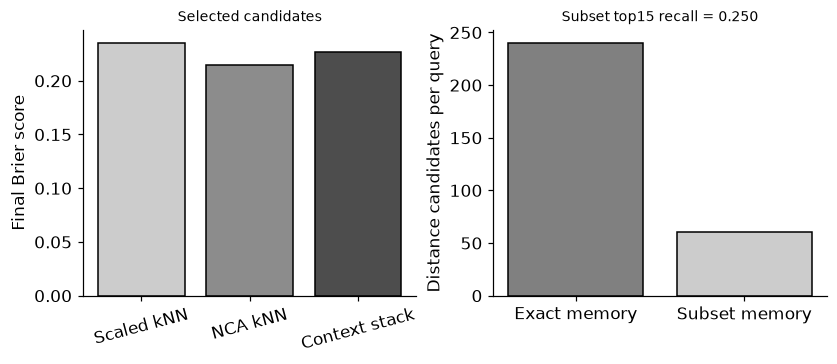

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NeighborhoodComponentsAnalysis,KNeighborsClassifier,NearestNeighbors
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss,log_loss,accuracy_score
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.kernel_approximation import RBFSampler,Nystroem
from scipy.spatial.distance import cdist
def generate(n):
 a=rng.normal(size=(n,12));b=(a[:,0]*a[:,1]>0).astype(int);b^=(rng.random(n)<.05).astype(int);return a,b
X,y=generate(240);Xd,yd=generate(120);Xt,yt=generate(300);all_ids=np.arange(len(y));iterations=[]
def encoder(a,b):
 sc=StandardScaler().fit(a);s=sc.transform(a);nca=NeighborhoodComponentsAnalysis(n_components=2,init='pca',max_iter=50,tol=1e-5,random_state=SEED).fit(s,b);A=nca.components_.copy();A*=np.sqrt(2)/np.linalg.norm(A);iterations.append(int(nca.n_iter_));return sc,A
def mapped(enc,a):return enc[0].transform(a)@enc[1].T
full=encoder(X,y);sc=full[0];representations={'Scaled kNN':(sc.transform(X),sc.transform(Xd),sc.transform(Xt)),'NCA kNN':(mapped(full,X),mapped(full,Xd),mapped(full,Xt))};models={};rows=[]
def metric(name,dev,p,extra):return {'candidate':name,'development_brier':dev,'final_brier':float(brier_score_loss(yt,p)),'final_log_loss_clipped_1e6':float(log_loss(yt,np.clip(p,1e-6,1-1e-6))),'final_accuracy_probability_half':float(accuracy_score(yt,p>=.5)),**extra}
for name,(s,d,t) in representations.items():
 candidates=[]
 for k in [5,15,31]:
  for weight in ['uniform','distance']:
   model=KNeighborsClassifier(k,weights=weight).fit(s,y);candidates.append((float(brier_score_loss(yd,model.predict_proba(d)[:,1])),model,k,weight))
 dev,model,k,weight=min(candidates,key=lambda v:v[0]);p=model.predict_proba(t)[:,1];rows.append(metric(name,dev,p,{'k':k,'weights':weight,'development_candidates':6}));models[name]=model
folds=[];seen=np.zeros(len(y),int)
for memory,query in StratifiedKFold(5,shuffle=True,random_state=SEED).split(X,y):
 assert not set(memory)&set(query);enc=encoder(X[memory],y[memory]);folds.append((memory,query,enc));seen[query]+=1
np.testing.assert_array_equal(seen,np.ones(len(y),int))
def context(query,pool,labels,enc,temp,query_ids=None,pool_ids=None):
 if query_ids is not None:assert not set(query_ids)&set(pool_ids)
 d=cdist(mapped(enc,query),mapped(enc,pool),'sqeuclidean');ix=np.argsort(d,axis=1)[:,:15];chosen=np.take_along_axis(d,ix,axis=1);logw=-chosen/temp;w=np.exp(logw-logw.max(axis=1,keepdims=True));w/=w.sum(axis=1,keepdims=True);np.testing.assert_allclose(w.sum(axis=1),1,atol=1e-12);mean_y=(w*labels[ix]).sum(axis=1);diff=np.einsum('ij,ijk->ik',w,pool[ix])-query;return np.column_stack([query,mean_y,diff,(w*chosen).sum(axis=1)])
options=[]
for temp in [.05,.2,1]:
 oof=np.zeros((len(y),26))
 for memory,query,enc in folds:oof[query]=context(X[query],X[memory],y[memory],enc,temp,query, memory)
 meta_sc=StandardScaler().fit(oof);head=LogisticRegression(C=1,max_iter=300).fit(meta_sc.transform(oof),y);d=context(Xd,X,y,full,temp);dev=float(brier_score_loss(yd,head.predict_proba(meta_sc.transform(d))[:,1]));options.append((dev,temp,head,meta_sc))
dev,temp,head,meta_sc=min(options,key=lambda v:v[0]);p=head.predict_proba(meta_sc.transform(context(Xt,X,y,full,temp)))[:,1];rows.append(metric('Retrieval context stack',dev,p,{'temperature':temp,'development_candidates':3,'OOF_folds':5,'neighbor_context_size':15,'meta_features':26,'reference_TabR_executed':False}));assert all(r['final_brier']>=0 for r in rows)
RESULTS['candidates']=rows;RESULTS['NCA']={'fit_n_iter_full_then_folds':iterations,'max_iter':50,'tol':1e-5,'convergence_asserted':False,'map_dimensions':2,'neural_ModernNCA_executed':False};RESULTS['roles']={'training':240,'development':120,'final':300,'nuisance_dimensions':10,'first_level_OOF_query_overlap_with_memory':0,'query_label_in_own_first_level_fit':False};RESULTS['invalid_self_lookup']={'training_accuracy':float(accuracy_score(y,KNeighborsClassifier(1).fit(sc.transform(X),y).predict(sc.transform(X)))),'valid_assessment':False,'used_for_selection':False}
# Predeclared memory budget: geometric audit uses final descriptors, never final labels.
full_keys=mapped(full,X);query_keys=mapped(full,Xt);subset=rng.choice(len(y),60,replace=False);exact=NearestNeighbors(n_neighbors=15).fit(full_keys).kneighbors(query_keys,return_distance=False);approx_local=NearestNeighbors(n_neighbors=15).fit(full_keys[subset]).kneighbors(query_keys,return_distance=False);approx=subset[approx_local];recall=float(np.mean([len(set(a)&set(b))/15 for a,b in zip(exact,approx)]));assert 0<=recall<=1
RESULTS['search_budget']={'full_records':240,'subset_records':60,'top15_recall':recall,'exact_distance_candidates_per_query':240,'subset_distance_candidates_per_query':60,'named_ANN_index_claimed':False};RESULTS['retrieval_array_bytes']={'raw_training_float64':int(X.nbytes),'two_dimensional_keys':int(full_keys.nbytes),'int_labels':int(y.nbytes),'linear_NCA_map':int(full[1].nbytes),'excludes':'Python objects, library overhead, temporary arrays, complete process RSS'}
fig,axes=plt.subplots(1,2,figsize=(7.5,3.2));pos=np.arange(3);axes[0].bar(pos,[r['final_brier'] for r in rows],color=['.8','.55','.3'],edgecolor='black');axes[0].set(xticks=pos,xticklabels=['Scaled kNN','NCA kNN','Context stack'],ylabel='Final Brier score',title='Selected candidates');axes[0].tick_params(axis='x',labelrotation=15);axes[1].bar([0,1],[240,60],color=['.5','.8'],edgecolor='black');axes[1].set(xticks=[0,1],xticklabels=['Exact memory','Subset memory'],ylabel='Distance candidates per query',title=f'Subset top15 recall = {recall:.3f}');plt.show()


<a id="approximation"></a>
## Approximate a kernel under a defined array budget

On the same standardized training inputs, fit a64-dimensional random Fourier map and a64-landmark Nystroem map for RBF gamma.2. Compare reconstructed development Gram matrices against the exact RBF matrix by relative Frobenius error. This isolated algebra audit does not train or select another response model. Record stored training features and transformation-array bytes, separately from the dense240×240 training Gram. Shared raw inputs, Python objects, workspaces and process RSS are excluded. A manual cosine map must match RBFSampler; both approximate Gram matrices must be positive semidefinite within arithmetic tolerance. Lower reconstruction error alone does not guarantee lower prediction error, and candidate-count reductions are not measured latency speedups.


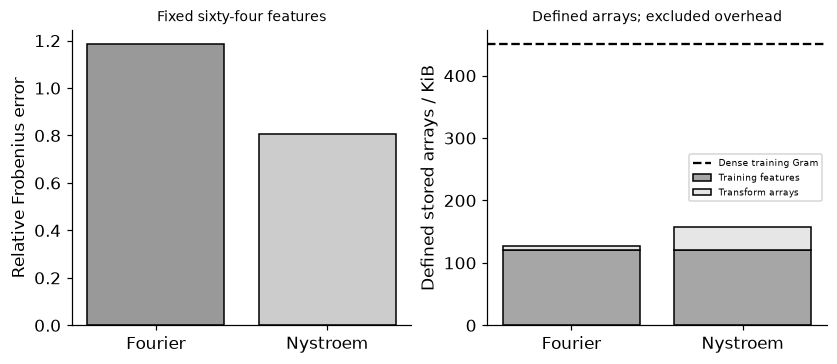

In [3]:
s=sc.transform(X);d=sc.transform(Xd);truth=rbf_kernel(d,d,gamma=.2);dense=rbf_kernel(s,s,gamma=.2);approximations=[]
for name,transform in [('Random Fourier',RBFSampler(gamma=.2,n_components=64,random_state=SEED)),('Nystroem',Nystroem(gamma=.2,n_components=64,random_state=SEED))]:
 feature=transform.fit_transform(s);held=transform.transform(d);gram=held@held.T;assert np.linalg.eigvalsh(gram).min()>-1e-9
 if name=='Random Fourier':
  manual=np.sqrt(2/64)*np.cos(s@transform.random_weights_+transform.random_offset_);np.testing.assert_allclose(feature,manual,atol=1e-12);parameter_bytes=transform.random_weights_.nbytes+transform.random_offset_.nbytes
 else:parameter_bytes=transform.components_.nbytes+transform.normalization_.nbytes
 approximations.append({'method':name,'features':64,'development_Gram_relative_Frobenius_error':float(np.linalg.norm(gram-truth)/np.linalg.norm(truth)),'training_feature_bytes':int(feature.nbytes),'transform_parameter_bytes':int(parameter_bytes),'dense_training_Gram_bytes_reference':int(dense.nbytes)})
RESULTS['kernel_approximations']=approximations;fig,axes=plt.subplots(1,2,figsize=(7.5,3.2));pos=np.arange(2);axes[0].bar(pos,[r['development_Gram_relative_Frobenius_error'] for r in approximations],color=['.6','.8'],edgecolor='black');axes[0].set(xticks=pos,xticklabels=['Fourier','Nystroem'],ylabel='Relative Frobenius error',title='Fixed sixty-four features');axes[1].bar(pos,[r['training_feature_bytes']/1024 for r in approximations],color='.65',edgecolor='black',label='Training features');axes[1].bar(pos,[r['transform_parameter_bytes']/1024 for r in approximations],bottom=[r['training_feature_bytes']/1024 for r in approximations],color='.9',edgecolor='black',label='Transform arrays');axes[1].axhline(dense.nbytes/1024,color='black',ls='--',label='Dense training Gram');axes[1].set(xticks=pos,xticklabels=['Fourier','Nystroem'],ylabel='Defined stored arrays / KiB',title='Defined arrays; excluded overhead');axes[1].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_086','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['linear supervised NCA and tuned neighbors', 'fold-contained label-valued retrieval context', 'candidate-budget recall and array memory', 'random Fourier and Nystroem Gram approximations'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["linear supervised NCA and tuned neighbors", "fold-contained label-valued retrieval context", "candidate-budget recall and array memory", "random Fourier and Nystroem Gram approximations"], "elapsed_seconds": 0.446, "example_id": "code_086", "hardware": "Darwin arm64 CPU", "results": {"NCA": {"convergence_asserted": false, "fit_n_iter_full_then_folds": [28, 33, 36, 46, 46, 51], "map_dimensions": 2, "max_iter": 50, "neural_ModernNCA_executed": false, "tol": 1e-05}, "candidates": [{"candidate": "Scaled kNN", "development_brier": 0.21819303109176136, "development_candidates": 6, "final_accuracy_probability_half": 0.61, "final_brier": 0.23515568290757416, "final_log_loss_clipped_1e6": 0.6627299830520978, "k": 15, "weights": "distance"}, {"candidate": "NCA kNN", "development_brier": 0.1628888888888889, "development_candidates": 6, "final_accuracy_probability_half": 0.68, "final_brier": 0.21454814814814815, "final_log_loss_clipped_1e6": 0.772